# **Start Section:**

In [1]:
# FIX K1: same notebook runs on Google Colab (Drive) or Kaggle (internet on).
# On Kaggle the working dir is /kaggle/working, so the original "./drive/MyDrive/..." paths
# below are reused unchanged; the dataset is copied there as train.csv / test.csv.
import os, glob, shutil
IN_KAGGLE = os.path.exists("/kaggle/working")
if IN_KAGGLE:
    _data_dir = "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/data"
    os.makedirs(_data_dir, exist_ok=True)
    shutil.copy(glob.glob("/kaggle/input/**/d04_a.csv", recursive=True)[0], f"{_data_dir}/train.csv")  # water_quality_wqi train
    shutil.copy(glob.glob("/kaggle/input/**/d04_b.csv", recursive=True)[0], f"{_data_dir}/test.csv")   # water_quality_wqi test
    print("Kaggle: water_quality_wqi data copied to", _data_dir)
else:
    from google.colab import drive
    drive.mount('/content/drive')


Kaggle: water_quality_wqi data copied to ./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/data


In [2]:
# FIX K1: original Colab install block kept as-is (runs only on Colab).
# On Kaggle: install only the packages the Kaggle image lacks, pinned to the Colab versions,
# and do NOT restart the kernel.
if IN_KAGGLE:
    !pip install -q optuna==4.6.0 optunahub==0.4.0 cmaes==0.12.0 xgboost==3.1.2 catboost==1.2.8 gpboost==1.6.1 ngboost==0.5.8 pgbm==2.2.0 pytorch-tabnet2==4.5.3 interpret==0.7.4 lime==0.2.0.1 bayesian-optimization==3.2.0 properscoring==0.1 XlsxWriter==3.2.9 mapie==0.6.0 puncc==0.8.0
else:
    import os
    os.environ["PIP_CONSTRAINT"] = "/tmp/numpy_constraint.txt"
    !echo "numpy==1.26.4" > /tmp/numpy_constraint.txt

    !pip uninstall -y torch torchaudio torchvision \
        torchao torchcodec torchdata torchtune torchsummary -q 2>/dev/null

    !pip uninstall -y tensorflow tensorflow-text tensorflow-hub tf-keras \
        tensorflow_decision_forests tensorflow-probability \
        tensorflow-Datasets tensorflow-metadata -q 2>/dev/null

    !pip uninstall -y numpy scikit-learn shap xgboost lightgbm dask \
        seaborn plotly openpyxl Cython catboost interpret lime -q 2>/dev/null

    !pip install numpy==1.26.4 -q
    !pip install scikit-learn==1.6.1 -q
    !pip install torch==2.9.0 -q

    !pip install lightgbm==4.6.0 -q
    !pip install xgboost==3.1.2 -q
    !pip install catboost==1.2.8 -q
    !pip install gpboost==1.6.1 -q
    !pip install ngboost==0.5.8 -q
    !pip install pgbm==2.2.0 -q
    !pip install pytorch-tabnet2==4.5.3 -q

    !pip install bayesian-optimization==3.2.0 -q
    !pip install optuna==4.6.0 -q
    !pip install optunahub==0.4.0 -q
    !pip install cmaes==0.12.0 -q

    !pip install shap==0.44.0 -q
    !pip install lime==0.2.0.1 -q
    !pip install interpret==0.7.4 -q

    !pip install mapie==0.6.0 -q
    !pip install puncc==0.8.0 -q
    !pip install skorch==1.3.1 -q
    !pip install properscoring==0.1 -q

    !pip install dask[dataframe]==2025.12.0 -q
    !pip install cython==3.0.12 -q
    !pip install seaborn==0.13.2 -q
    !pip install plotly==5.24.1 -q
    !pip install kaleido==1.2.0 -q
    !pip install openpyxl==3.1.5 -q
    !pip install XlsxWriter==3.2.9 -q
    !pip install cp==2020.12.3 -q

    !pip install numpy==1.26.4 --force-reinstall --no-deps -q

    os._exit(0)


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


# **Imports**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.svm import SVR
import ngboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from gpboost import GPBoostRegressor
from ngboost import NGBRegressor
import optuna
import optunahub
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from interpret import show
from interpret.blackbox import LimeTabular, ShapKernel
from optuna.samplers import RandomSampler
import random
import time
from ngboost.distns import Normal
from ngboost.scores import LogScore
from scipy.stats import norm
from optuna.samplers import BaseSampler
from optuna.samplers import GridSampler
from optuna.samplers import TPESampler
from optuna.samplers import PartialFixedSampler
from optuna.samplers import CmaEsSampler
from optuna.samplers import QMCSampler
from optuna.samplers import NSGAIIISampler
from optuna.samplers import NSGAIISampler
from optuna.samplers import BruteForceSampler
from optuna.samplers import GPSampler
from interpret import set_visualize_provider
from interpret.provider import InlineProvider
from interpret.glassbox import ExplainableBoostingRegressor
from interpret import show
import plotly.express as px
from io import BytesIO
from openpyxl import Workbook, load_workbook
import os
import properscoring as ps
import io
from openpyxl.drawing.image import Image as openpyxlImage
import warnings
import xlsxwriter
from openpyxl.drawing.image import Image
from pgbm.sklearn import HistGradientBoostingRegressor
import torch
from pgbm.torch import PGBM
import plotly.graph_objects as go
warnings.filterwarnings('ignore')
import pickle
import json
from mapie.subsample import Subsample
from sklearn.model_selection import PredefinedSplit  # FIX M3


def _split_cv(n, seed, calib_fraction=0.5):
    """FIX B9: one fit / calibration split (split conformal) written as a PredefinedSplit, because
    MAPIE 0.6 accepts only BaseCrossValidator objects and rejects ShuffleSplit.
    A seeded random half of the training rows is used for calibration."""
    import numpy as _np
    fold = -_np.ones(n, dtype=int)                      # -1 = used to fit the model
    fold[_np.random.RandomState(seed).permutation(n)[: int(round(calib_fraction * n))]] = 0   # 0 = calibration
    return PredefinedSplit(fold)
from mapie.regression import MapieRegressor
from deel.puncc.metrics import regression_sharpness, regression_mean_coverage
from deel.puncc.api.prediction import BasePredictor, DualPredictor
from deel.puncc.regression import SplitCP, CVPlus, CQR
from deel.puncc.plotting import plot_prediction_intervals
from sklearn.model_selection import train_test_split
from typing_extensions import TypedDict
from typing import Union
from mapie.metrics import regression_coverage_score
from sklearn.model_selection import KFold
from PIL import Image as PImage
from openpyxl.utils.dataframe import dataframe_to_rows
from pytorch_tabnet import TabNetRegressor

[1/2] c++ -MMD -MF splitgain_cpu.o.d -DTORCH_EXTENSION_NAME=split_decision -DTORCH_API_INCLUDE_EXTENSION_H -isystem /usr/local/lib/python3.13/dist-packages/torch/include -isystem /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -isystem /usr/include/python3.13 -fPIC -std=c++17 -c /usr/local/lib/python3.13/dist-packages/pgbm/torch/splitgain_cpu.cpp -o splitgain_cpu.o 


[2/2] c++ splitgain_cpu.o -shared -L/usr/local/lib/python3.13/dist-packages/torch/lib -lc10 -ltorch_cpu -ltorch -ltorch_python -o split_decision.so


I0000 00:00:1795406052.073422      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795406073.224569      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
# Go to find & replace button and replace (water_quality_wqi_uncertainty_analysis) with your folder name. Rename your train and test Dataset as train.csv and test.csv.
# Modify the names of the feature in the below cell.
# Replace (str) with actual data label name.

In [5]:
feature_names = ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9', 'R10', 'R11', 'R12', 'R13', 'R14', 'R15', 'R16', 'R17', 'R18', 'R19', 'R20', 'R21', 'R22', 'R23', 'R24', 'R25', 'R26', 'R27', 'R28', 'R29', 'R30', 'R31', 'R32', 'R33', 'R34', 'R35', 'R36', 'R37', 'R38', 'R39', 'R40', 'R41', 'R42', 'R43', 'R44', 'R45', 'R46', 'R47', 'R48', 'R49', 'R50', 'R51', 'R52', 'R53', 'R54', 'R55', 'R56', 'R57', 'R58', 'R59', 'R60', 'R61', 'R62', 'R63', 'R64', 'R65', 'R66', 'R67', 'R68', 'R69', 'R70', 'R71', 'R72', 'R73', 'R74', 'R75', 'R76', 'R77', 'R78', 'R79', 'R80', 'R81', 'R82', 'R83', 'R84', 'R85', 'R86', 'R87', 'R88', 'R89', 'R90', 'R91', 'R92', 'R93', 'R94', 'R95', 'R96', 'R97', 'R98', 'R99', 'R100', 'R101', 'R102', 'R103', 'R104', 'R105', 'R106', 'R107', 'R108', 'R109', 'R110', 'R111', 'R112', 'R113', 'R114', 'R115', 'R116', 'R117', 'R118', 'R119', 'R120', 'R121', 'R122', 'R123', 'R124', 'R125', 'R126', 'R127', 'R128', 'R129', 'R130', 'R131', 'R132', 'R133', 'R134', 'R135', 'R136', 'R137', 'R138', 'R139', 'R140', 'R141', 'R142', 'R143', 'R144', 'R145', 'R146', 'R147', 'R148', 'R149', 'R150', 'R151']
TARGET_LABEL = 'WQI'  # FIX B12: target name used in plot labels (was 'str', the concrete dataset's target, on every dataset)

In [6]:
train_data_path = "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/data/train.csv"
test_data_path = "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/data/test.csv"
train_data = pd.read_csv(train_data_path)
test_data = pd.read_csv(test_data_path)
print("Training data loaded successfully.")
print("Test data loaded successfully.")

Training data loaded successfully.
Test data loaded successfully.


In [7]:
print("\nShape of training data:", train_data.shape)
print("First 5 rows of training data:\n", train_data.head(5))
print("\nShape of test data:", test_data.shape)
print("First 5 rows of test data:\n", test_data.head(5))


Shape of training data: (190, 152)
First 5 rows of training data:
        R1      R2      R3      R4      R5      R6      R7      R8      R9  \
0  3.5960  3.6080  3.0100  3.6130  3.3760  2.2780  1.3410  3.4570  3.3540   
1  2.9540  3.0470  3.1160  4.2640  4.4090  3.4810  2.3760  3.4030  3.4320   
2  2.4870  2.9430  2.5290  3.7280  2.9870  1.8890  1.9960  2.1020  1.6180   
3  1.3640  1.4186  1.3789  1.4776  1.5063  1.4047  1.2648  1.5166  1.5443   
4  1.3074  1.3820  1.3476  1.3986  1.3403  1.3004  1.3719  1.3984  1.3865   

      R10  ...    R143    R144    R145    R146    R147   R148    R149    R150  \
0  1.9900  ...  2.7930  1.9660  2.3070  1.5280  1.9380  3.371  2.2060  1.5220   
1  2.6350  ...  3.0260  2.3530  2.0400  1.7400  2.6250  4.026  2.9010  1.7450   
2  1.2720  ...  1.2760  1.5990  1.8610  1.0290  1.8690  3.905  2.3200  1.3310   
3  1.3834  ...  1.2223  1.0919  1.0995  1.0856  1.1728  1.315  1.2341  1.0753   
4  1.3964  ...  1.1691  1.0689  1.1230  1.1384  1.1810  1.235  1

In [8]:
X_train = train_data.iloc[:, :-1]
y_train = train_data.iloc[:, -1]
X_test = test_data.iloc[:, :-1]
y_test = test_data.iloc[:, -1]
# FIX D4 / D5 (approved 2026-11-22): settings that follow the test-set size
N_BINS = max(2, min(10, len(y_test) // 10))  # D4: bins for binned metrics (was 10 on every dataset; pile: 2-3 points per bin)
COP_T_BURNIN = min(50, len(y_test) // 2)  # D5: COP burn-in (was 50, so with < 50 test points COP's correction never started)
x_test= X_test
print("\nShape of X_train:", X_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_test:", y_test.shape)


Shape of X_train: (190, 151)
Shape of y_train: (190,)
Shape of X_test: (82, 151)
Shape of y_test: (82,)


In [9]:
# Apply z-score normalization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Print the first five rows of the normalized data
print("\nFirst five rows of normalized X_train:")
print(X_train[:5])

print("\nFirst five rows of normalized X_test:")
print(X_test[:5])


First five rows of normalized X_train:
[[ 1.22103295  1.13089815  0.61081314  0.73682842  0.54673262 -0.0261968
  -0.51531151  0.70303503  0.5510272  -0.2441054   0.17648144  0.69219002
   0.9485328   0.82481901  0.34566436 -0.40609522 -0.463771    0.43872889
   0.89421381  1.05057715  1.04529849  1.03900179  0.42575888  0.173456
   0.45642529  0.83037026  0.89010153  0.77972274  0.71866378  0.6206252
   0.82167079  0.97412629  0.67298061  0.39758814  0.52679374  0.94375937
   0.74197071  0.86577935  1.27064247  1.51437415  0.46596778 -0.30888056
  -0.12461695  0.49591603  0.72957494  0.5811918   0.31848773  0.53466849
   0.20246884  0.11900459  0.99635035  0.72105768  0.43065398  0.36777539
   0.10638109 -0.0263905   0.2318847   0.82337505  0.74363607  0.85248236
   0.71669043 -0.11909161 -0.10843386  0.51688952  0.84551287 -0.1576873
  -0.12716017  0.37884167  0.35396679 -0.24556803  0.07962918  0.82628894
   0.54494889  1.02963853  1.17379609  0.60350175 -0.17692428 -0.31350223
   

# **Functions:**

In [10]:
# Define the model classes
model_classes = {
    'Random Forest': RandomForestRegressor,
    'Gradient Boosting': GradientBoostingRegressor,
    'XGBoost': XGBRegressor,
    'LightGBM': LGBMRegressor,
    'GPBoost': GPBoostRegressor,
    'CatBoost': CatBoostRegressor,
    'HistGradientBoosting': HistGradientBoostingRegressor,
    'TabNet': TabNetRegressor,
    'NGBoost': NGBRegressor
}

def _ensure_excel_file(path):
    import os
    import pandas as pd
    if not os.path.exists(path):
        parent = os.path.dirname(path)
        if parent:
            os.makedirs(parent, exist_ok=True)
        pd.DataFrame().to_excel(path)
    return path

In [11]:
def get_best_model_params(results, model_name):
    # Map model names to dictionary keys, assuming keys are strings like 'XGBoost' and not objects
    model_keys = {
        'LightGBM': 'LightGBM',
        'XGBoost': 'XGBoost',
        'GPBoost': 'GPBoost',
        'NGBoost': 'NGBoost',
        'GradientBoosting': 'Gradient Boosting',
        'HGBR' : 'HistGradientBoosting',
        'CatBoost' : 'CatBoost',
        'TabNet' : 'TabNet',
        'PGBM' : 'PGBM'
    }

    # Ensure the requested model name is valid
    if model_name not in model_keys:
        raise ValueError(f"Model name '{model_name}' is not recognized. Available models are: {list(model_keys.keys())}")

    # Filter out entries for the specified model
    model_entries = {key: value for key, value in results.items() if key[0] == model_keys[model_name]}

    # Find the entry with the best (lowest) 'best_score'
    best_entry_key, best_entry_value = min(model_entries.items(), key=lambda item: item[1]['best_score'])

    # Return the best hyperparameters
    return best_entry_value['best_params']

In [12]:
# FIX M4: one miscoverage level for every method in this notebook (MAPIE and PUNCC).
# Was: MAPIE used 0.05 and PUNCC 0.1, so their coverages/widths could not be compared.
ALPHA = 0.1   # target coverage = 1 - ALPHA = 90%


In [13]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test.to_numpy()[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test.to_numpy()[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.to_numpy().ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE(model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path):
    """
    Train and plot conformal prediction intervals using different strategies and save the plots and
    table of ymin/ymax/y_pred to different worksheets in an Excel file for each strategy.

    Parameters:
    - model_class: The class of the model to be used (e.g., LGBMRegressor).
    - best_params: Dictionary of best parameters for the model.
    - X_train: Training features.
    - y_train: Training target.
    - X_test: Test features.
    - y_test: Test target.
    - model_name: Name of the model for labeling purposes.
    - excel_file_path: Path to the Excel file where the plots will be saved.
    """
    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    # Define miscoverage
    MISCOVERAGE: float = ALPHA  # FIX M4: was 0.05  # MISCOVERAGE = alpha # CONFIDENCE = 1-alpha
    warnings.filterwarnings("ignore")  # to suppress them

    # Create output directory
    os.makedirs('output/regression', exist_ok=True)

    # Define strategies and parameters
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Define base estimators
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    # Train strategies using MAPIE
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred) # Corrected line: Removed y_test
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test.to_numpy() - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the results for the test set
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names) * 3 + 1 + len(_strategies) # Strategy plots + Goodness plots + Width plots + Comparison plot + Coverage vs Width plots
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))

    plot_index = 0 # Keep track of the current plot index

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot for comparison
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet for the plots
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = 'conformal_predictions_MAPIE'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        all_rows = []
        y_true_np = y_test.to_numpy().ravel()  # To save multiple conversions
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()



In [14]:
# FIX M1: Conformalized Quantile Regression (Romano et al. 2019) needs models of the
# alpha/2 and 1-alpha/2 QUANTILES. Was: both "quantile" models were the same mean model, so the
# band was mean +/- a constant (split conformal with extra steps), not CQR.
# QuantileModel fits each base model at quantile level q in the way that model supports:
#   native quantile loss  - LightGBM, GPBoost, XGBoost, sklearn GradientBoosting, CatBoost, TabNet
#   predictive distribution - NGBoost (ppf), PGBM (sampled forecasts), pgbm HistGradientBoosting (mean, std)
from scipy.stats import norm as _norm
from sklearn.base import BaseEstimator, RegressorMixin


class QuantileModel(BaseEstimator, RegressorMixin):
    def __init__(self, model_class, params, q):
        self.model_class = model_class
        self.params = params
        self.q = q

    def _kind(self):
        return self.model_class.__name__

    def fit(self, X, y):
        p, q, name = dict(self.params or {}), self.q, self._kind()
        X_ = np.asarray(X)
        y_ = np.asarray(y).ravel()
        if name in ("LGBMRegressor", "GPBoostRegressor"):
            p.update(objective="quantile", alpha=q)
        elif name == "XGBRegressor":
            p.update(objective="reg:quantileerror", quantile_alpha=q)
        elif name == "GradientBoostingRegressor":
            p.update(loss="quantile", alpha=q)
        elif name == "CatBoostRegressor":
            p.pop("objective", None)
            p.update(loss_function=f"Quantile:alpha={q}")
        if "TabNet" in name:
            import torch as _torch

            def _pinball(y_pred, y_true):
                e = y_true - y_pred
                return _torch.mean(_torch.maximum(q * e, (q - 1) * e))
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_, loss_fn=_pinball)
        else:
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_)
        return self

    def predict(self, X):
        X_, q, name = np.asarray(X), self.q, self._kind()
        if name == "NGBRegressor":
            return np.asarray(self.model_.pred_dist(X_).ppf(q)).ravel()
        if name == "PGBMWrapper":
            samples = self.model_.model.predict_dist(X_)
            samples = samples.cpu().numpy() if hasattr(samples, "cpu") else np.asarray(samples)
            return np.quantile(samples, q, axis=0).ravel()
        if name == "HistGradientBoostingRegressor":   # pgbm.sklearn: probabilistic HGBR
            mu, sd = self.model_.predict(X_, return_std=True)
            return (np.asarray(mu) + np.asarray(sd) * _norm.ppf(q)).ravel()
        return np.asarray(self.model_.predict(X_)).ravel()


In [15]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC(
    X_train, y_train, X_test, y_test, best_scores_autosampler, model_class,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Determine the default parameters for the model, or use provided ones
    if model_params is None:
        if model_class.__name__ == 'LGBMRegressor':
            model_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
        else:
            model_params = {}

    # Initialize and train the model using the provided class and parameters
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_test, y_test, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test, y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Wrap the model in a BasePredictor
    base_predictor = BasePredictor(model, is_trained=True)

    # Initialize and fit the SplitCP conformal predictor
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)

    # Compute prediction intervals and metrics on the test set using SplitCP
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for SplitCP
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))

    axs[0].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Initialize and fit the CVPlus conformal predictor
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)

    # Compute prediction intervals and metrics on the test set using CVPlus
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, cvplus, alpha)
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CVPlus - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CVPlus
    axs[1].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Split the training data into proper training (fit) set and calibration set
    X_fit, X_calib, y_fit, y_calib = train_test_split(
        X_train, y_train, test_size=0.5, random_state=0
    )

    # Fit the upper and lower quantile models
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)

    _ = upper_quantile_model.fit(X_fit, y_fit)
    _ = lower_quantile_model.fit(X_fit, y_fit)

    # Wrap the upper and lower quantile models in a dual predictor
    dualpredictor = DualPredictor(
        [lower_quantile_model, upper_quantile_model], is_trained=[True, True]
    )

    # Initialize the CQR conformal predictor
    cqr = CQR(
        dualpredictor, train=False
    )  # train=False to use the pre-trained dual predictor

    # Compute nonconformity scores on the calibration set
    cqr.fit(X_calib=X_calib, y_calib=y_calib)

    # Compute prediction intervals and metrics on the test set
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness, coverage = evaluate_cp(X_test, y_test, cqr, alpha)

    print(f"CQR - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CQR - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CQR
    axs[2].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    # Save all plots and values to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

In [16]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis(
    X_train,
    y_train,
    X_test,
    y_test,
    model_cls,
    model_params,
    excel_file_path=None,
    suptitle: str = "Prediction Intervals"
) -> None:
    # Initialize and fit the model with MAPIE using provided parameters
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    # Visualization function
    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [y_train.min(), y_train.max()],
            [y_train.min(), y_train.max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        y_test,
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        mapie = MapieRegressor(mdl, **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_2')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

# **Tuned Parameters**

In [17]:
# FIX K2: load the tuning results saved by hyperparameter_tuning/Optuna_autosampler.ipynb
# (was: a hand-pasted copy of an older tuning run that had been selected on the TEST set).
import pickle
if IN_KAGGLE:
    _bp = glob.glob("/kaggle/input/**/hyperparameter_tuning/best_params.pkl", recursive=True)[0]
else:
    _bp = "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/hyperparameter_tuning/best_params.pkl"
with open(_bp, "rb") as f:
    best_scores_autosampler = pickle.load(f)
print("Loaded tuning results from", _bp, "-", len(best_scores_autosampler), "model x pruner entries")


Loaded tuning results from /kaggle/input/datasets/daneshselwal/water-quality-wqi-tuned-params/hyperparameter_tuning/best_params.pkl - 80 model x pruner entries


# **Conformal Predictions with Lightgbm**

In [18]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')

In [19]:
conformal_predictions_MAPIE(LGBMRegressor, best_params, X_train, y_train, X_test, y_test, "LightGBM","./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 31.9003
  Interval Width: 90.9363
  Coverage: 86.59%
  CWC: 103.1351
  SSC: 9287.0372

Strategy: Cross Validation +
  RMSE: 31.9003
  Interval Width: 100.1750
  Coverage: 89.02%
  CWC: 111.1698
  SSC: 11058.9928

Strategy: Jackknife+ after Bootstrapping
  RMSE: 31.9003
  Interval Width: 90.5668
  Coverage: 89.02%
  CWC: 100.5071
  SSC: 9221.6145



In [20]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, LGBMRegressor,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 122.005
SplitCP - Average coverage: 91.463%


CVPlus - Average prediction intervals width (sharpness): 80.822
CVPlus - Average coverage: 86.585%
CQR - Average prediction intervals width (sharpness): 148.587
CQR - Average coverage: 98.780%


In [21]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, LGBMRegressor, best_params, "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx", "LightGBM Prediction Intervals")

# **Conformal Predictions with XGBoost**

In [22]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')

In [23]:
conformal_predictions_MAPIE(XGBRegressor, best_params, X_train, y_train, X_test, y_test, "XGBoost", "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 28.7433
  Interval Width: 76.9697
  Coverage: 82.93%
  CWC: 90.1109
  SSC: 6750.5175

Strategy: Cross Validation +
  RMSE: 28.7433
  Interval Width: 96.1779
  Coverage: 89.02%
  CWC: 106.7340
  SSC: 10097.3406

Strategy: Jackknife+ after Bootstrapping
  RMSE: 28.7433
  Interval Width: 81.3887
  Coverage: 86.59%
  CWC: 92.3067
  SSC: 7452.2169



In [24]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, XGBRegressor,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 100.576
SplitCP - Average coverage: 91.463%


CVPlus - Average prediction intervals width (sharpness): 84.441
CVPlus - Average coverage: 89.024%


CQR - Average prediction intervals width (sharpness): 164.040
CQR - Average coverage: 98.780%


In [25]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, XGBRegressor, best_params,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx", "XGBR Prediction Intervals")

# **Conformal Predictions with GPBoost**

In [26]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')

In [27]:
conformal_predictions_MAPIE(GPBoostRegressor, best_params, X_train, y_train, X_test, y_test, "GPBoost","./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 34.9096
  Interval Width: 89.8607
  Coverage: 78.05%
  CWC: 109.5862
  SSC: 9293.6229

Strategy: Cross Validation +
  RMSE: 34.9096
  Interval Width: 93.0890
  Coverage: 82.93%
  CWC: 108.9823
  SSC: 9917.3575

Strategy: Jackknife+ after Bootstrapping
  RMSE: 34.9096
  Interval Width: 75.0807
  Coverage: 81.71%
  CWC: 88.8150
  SSC: 6861.8501



In [28]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GPBoostRegressor,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx",best_params)

Finished loading model, total used 200 iterations
SplitCP - Average prediction intervals width (sharpness): 127.932
SplitCP - Average coverage: 90.244%
Finished loading model, total used 200 iterations


Finished loading model, total used 200 iterations
Finished loading model, total used 200 iterations
Finished loading model, total used 200 iterations
Finished loading model, total used 200 iterations


Finished loading model, total used 200 iterations
Finished loading model, total used 200 iterations
Finished loading model, total used 200 iterations
Finished loading model, total used 200 iterations


Finished loading model, total used 200 iterations
CVPlus - Average prediction intervals width (sharpness): 83.869
CVPlus - Average coverage: 81.707%
Finished loading model, total used 200 iterations
Finished loading model, total used 200 iterations
CQR - Average prediction intervals width (sharpness): 128.892
CQR - Average coverage: 87.805%


In [29]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GPBoostRegressor, best_params, "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx", "GPBoost Prediction Intervals")

# **Conformal Predictions with NGBoost**

In [30]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')

In [31]:
conformal_predictions_MAPIE(NGBRegressor, best_params, X_train, y_train, X_test, y_test, "NGBoost","./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 29.7219
  Interval Width: 92.8838
  Coverage: 89.02%
  CWC: 103.0783
  SSC: 9510.7873

Strategy: Cross Validation +
  RMSE: 29.6829
  Interval Width: 96.1149
  Coverage: 90.24%
  CWC: 96.1149
  SSC: 10137.0955

Strategy: Jackknife+ after Bootstrapping
  RMSE: 29.7836
  Interval Width: 86.3912
  Coverage: 89.02%
  CWC: 95.8731
  SSC: 8355.9596



In [32]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, NGBRegressor,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 133.428
SplitCP - Average coverage: 96.341%


CVPlus - Average prediction intervals width (sharpness): 84.073
CVPlus - Average coverage: 82.927%


CQR - Average prediction intervals width (sharpness): 123.143
CQR - Average coverage: 89.024%


In [33]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, NGBRegressor, best_params,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx","NGBoost Prediction Intervals")

# **Conformal Predictions with Gradient Boosting**

In [34]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')

In [35]:
conformal_predictions_MAPIE(GradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "GradientBoosting",  # FIX B3: was labelled "GPBoost"
   "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 31.4061
  Interval Width: 94.0147
  Coverage: 87.80%
  CWC: 105.4799
  SSC: 9825.1009

Strategy: Cross Validation +
  RMSE: 31.4061
  Interval Width: 113.5998
  Coverage: 95.12%
  CWC: 113.5998
  SSC: 13909.8102

Strategy: Jackknife+ after Bootstrapping
  RMSE: 31.4061
  Interval Width: 88.3991
  Coverage: 90.24%
  CWC: 88.3991
  SSC: 8802.7934



In [36]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GradientBoostingRegressor,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 157.958
SplitCP - Average coverage: 96.341%


CVPlus - Average prediction intervals width (sharpness): 82.968
CVPlus - Average coverage: 80.488%


CQR - Average prediction intervals width (sharpness): 188.349
CQR - Average coverage: 95.122%


In [37]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GradientBoostingRegressor, best_params, "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx", "Gradient Boosting Prediction Intervals")

# **Conformal Predictions with CatBoost**

In [38]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')

In [39]:
conformal_predictions_MAPIE(CatBoostRegressor, best_params, X_train, y_train, X_test, y_test, "CatBoost","./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 27.1575
  Interval Width: 84.5297
  Coverage: 89.02%
  CWC: 93.8074
  SSC: 7882.8028

Strategy: Cross Validation +
  RMSE: 27.1575
  Interval Width: 98.3911
  Coverage: 93.90%
  CWC: 98.3911
  SSC: 10432.0116

Strategy: Jackknife+ after Bootstrapping
  RMSE: 27.1575
  Interval Width: 92.4788
  Coverage: 91.46%
  CWC: 92.4788
  SSC: 9290.6734



In [40]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, CatBoostRegressor,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx",best_params)  # FIX M5: tuned params were not passed

SplitCP - Average prediction intervals width (sharpness): 113.363
SplitCP - Average coverage: 93.902%


CVPlus - Average prediction intervals width (sharpness): 97.283
CVPlus - Average coverage: 93.902%


CQR - Average prediction intervals width (sharpness): 142.693
CQR - Average coverage: 93.902%


In [41]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, CatBoostRegressor, best_params, "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx", "CatBoost Prediction Intervals")

# **Conformal Predictions with HistGradientBoosting**

In [42]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')

In [43]:
conformal_predictions_MAPIE(HistGradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "HGBR","./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 34.6112
  Interval Width: 92.6967
  Coverage: 79.27%
  CWC: 111.9143
  SSC: 9790.6195

Strategy: Cross Validation +
  RMSE: 34.6112
  Interval Width: 89.1813
  Coverage: 82.93%
  CWC: 104.4074
  SSC: 9184.4813

Strategy: Jackknife+ after Bootstrapping
  RMSE: 34.6112
  Interval Width: 83.1409
  Coverage: 86.59%
  CWC: 94.2940
  SSC: 8112.9047



In [44]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler,HistGradientBoostingRegressor,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 136.291
SplitCP - Average coverage: 96.341%


CVPlus - Average prediction intervals width (sharpness): 79.369
CVPlus - Average coverage: 86.585%


CQR - Average prediction intervals width (sharpness): 123.283
CQR - Average coverage: 91.463%


In [45]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, HistGradientBoostingRegressor, best_params,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx", "HGBR Prediction Intervals")

# **Conformal Predictions with PGBM**

In [46]:
class PGBMWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, **params):
        self.params = params
        self.model = None

    # FIX M6: MAPIE/sklearn clone() rebuilds the model from get_params(); with **params that was {},
    # so every MAPIE fit silently used PGBM defaults instead of the tuned settings.
    def get_params(self, deep=True):
        return dict(self.params)

    def set_params(self, **params):
        self.params.update(params)
        return self

    def fit(self, X, y):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        y_ = y.to_numpy() if hasattr(y, "to_numpy") else np.array(y)
        self.model = PGBM()
        self.model.train(
            train_set=(X_, y_),
            objective=mseloss_objective,
            metric=rmseloss_metric,
            params=self.params
        )
        return self

    def predict(self, X):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        return self.model.predict(X_).numpy()


In [47]:
# Assuming best_params is obtained correctly
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')

# Remove any conflicting parameters from best_params
incompatible_keys = ['Dist', 'Score']
for key in incompatible_keys:
    best_params.pop(key, None)

# Initialize PGBM model
pgbm_model = PGBM()
def mseloss_objective(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    gradient = yhat - y
    hessian = torch.ones_like(yhat)
    return gradient, hessian

def rmseloss_metric(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    loss = torch.sqrt(torch.mean((yhat - y) ** 2))
    return loss

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Fit the model
pgbm_model.train((X_train, y_train), objective=mseloss_objective, metric=rmseloss_metric, params=best_params)

# Predict the distribution
pred_dist = pgbm_model.predict_dist(X_test)

# Define the quantiles you want to predict
quantiles = [0.05, 0.1, 0.15, 0.2, 0.3,
             0.4, 0.5, 0.6, 0.7, 0.8,
             0.85, 0.9, 0.95]

# DataFrame to store predictions
predictions_PGBM_df = pd.DataFrame()

# Calculate and store quantiles
for q in quantiles:
    predictions_PGBM_df[q] = np.quantile(pred_dist, q, axis=0)

# Add actual target values to the DataFrame
predictions_PGBM_df['Actual'] = y_test.ravel()

# Print the DataFrame with predictions for each quantile
print(predictions_PGBM_df.head())

Training on CPU


Estimator 0/300, Train metric: 78.9001
Estimator 1/300, Train metric: 76.0510
Estimator 2/300, Train metric: 73.3512
Estimator 3/300, Train metric: 70.6507
Estimator 4/300, Train metric: 68.2775


Estimator 5/300, Train metric: 65.8602
Estimator 6/300, Train metric: 63.4633
Estimator 7/300, Train metric: 61.1513
Estimator 8/300, Train metric: 59.1168
Estimator 9/300, Train metric: 57.0578
Estimator 10/300, Train metric: 55.1212
Estimator 11/300, Train metric: 53.2731
Estimator 12/300, Train metric: 51.4449


Estimator 13/300, Train metric: 49.6976
Estimator 14/300, Train metric: 48.0189
Estimator 15/300, Train metric: 46.4079
Estimator 16/300, Train metric: 44.8642
Estimator 17/300, Train metric: 43.4459
Estimator 18/300, Train metric: 42.0784
Estimator 19/300, Train metric: 40.7679


Estimator 20/300, Train metric: 39.4945
Estimator 21/300, Train metric: 38.2714
Estimator 22/300, Train metric: 37.0826
Estimator 23/300, Train metric: 35.9078
Estimator 24/300, Train metric: 34.7604
Estimator 25/300, Train metric: 33.7132
Estimator 26/300, Train metric: 32.6903


Estimator 27/300, Train metric: 31.6972
Estimator 28/300, Train metric: 30.7656
Estimator 29/300, Train metric: 29.8942
Estimator 30/300, Train metric: 29.0440
Estimator 31/300, Train metric: 28.2583
Estimator 32/300, Train metric: 27.4161


... (56 outputs left out)

Estimator 281/300, Train metric: 1.6335
Estimator 282/300, Train metric: 1.6239
Estimator 283/300, Train metric: 1.6147
Estimator 284/300, Train metric: 1.6050
Estimator 285/300, Train metric: 1.5957
Estimator 286/300, Train metric: 1.5873


Estimator 287/300, Train metric: 1.5789
Estimator 288/300, Train metric: 1.5702
Estimator 289/300, Train metric: 1.5613
Estimator 290/300, Train metric: 1.5522
Estimator 291/300, Train metric: 1.5438
Estimator 292/300, Train metric: 1.5344


Estimator 293/300, Train metric: 1.5256
Estimator 294/300, Train metric: 1.5180
Estimator 295/300, Train metric: 1.5104
Estimator 296/300, Train metric: 1.5022
Estimator 297/300, Train metric: 1.4947
Estimator 298/300, Train metric: 1.4865
Estimator 299/300, Train metric: 1.4789


         0.05         0.1        0.15         0.2         0.3         0.4  \
0  273.770142  279.715088  283.416382  286.174072  288.616516  291.302368   
1  176.622406  177.881943  179.509827  179.796646  180.421417  180.856171   
2  404.486481  411.515717  417.013214  419.941040  424.265442  427.468536   
3  215.405060  216.753906  217.368576  217.773972  219.425995  220.388596   
4  128.763931  130.137955  131.065704  131.442856  132.016235  132.567017   

          0.5         0.6         0.7         0.8        0.85         0.9  \
0  291.961761  293.057007  294.430511  297.883331  300.085022  302.833832   
1  181.357117  181.681503  182.287033  183.428619  183.920181  184.590027   
2  429.695435  432.362762  436.334686  440.495880  441.710754  446.060730   
3  220.905426  221.782654  222.771255  224.122360  224.731979  225.387131   
4  133.197998  133.691971  134.486389  135.446228  135.856003  136.302917   

         0.95  Actual  
0  312.078064     315  
1  184.846405     167  
2 

Training on CPU
Estimator 0/300, Train metric: 78.9001
Estimator 1/300, Train metric: 76.0510


Estimator 2/300, Train metric: 73.3512
Estimator 3/300, Train metric: 70.6507
Estimator 4/300, Train metric: 68.2775


Estimator 5/300, Train metric: 65.8602
Estimator 6/300, Train metric: 63.4633
Estimator 7/300, Train metric: 61.1513
Estimator 8/300, Train metric: 59.1168
Estimator 9/300, Train metric: 57.0578


Estimator 10/300, Train metric: 55.1212
Estimator 11/300, Train metric: 53.2731
Estimator 12/300, Train metric: 51.4449


Estimator 13/300, Train metric: 49.6976
Estimator 14/300, Train metric: 48.0189
Estimator 15/300, Train metric: 46.4079
Estimator 16/300, Train metric: 44.8642


Estimator 17/300, Train metric: 43.4459
Estimator 18/300, Train metric: 42.0784
Estimator 19/300, Train metric: 40.7679


... (3,702 outputs left out)

Estimator 286/300, Train metric: 2.4765
Estimator 287/300, Train metric: 2.4618
Estimator 288/300, Train metric: 2.4480
Estimator 289/300, Train metric: 2.4344
Estimator 290/300, Train metric: 2.4355
Estimator 291/300, Train metric: 2.4219
Estimator 292/300, Train metric: 2.4082


Estimator 293/300, Train metric: 2.4093
Estimator 294/300, Train metric: 2.3955
Estimator 295/300, Train metric: 2.3822
Estimator 296/300, Train metric: 2.3685
Estimator 297/300, Train metric: 2.3547
Estimator 298/300, Train metric: 2.3412


Estimator 299/300, Train metric: 2.3278


Strategy: Split Conformal Prediction
  RMSE: 29.3756
  Interval Width: 81.2316
  Coverage: 85.37%
  CWC: 93.1192
  SSC: 7461.5029

Strategy: Cross Validation +
  RMSE: 29.3756
  Interval Width: 85.8082
  Coverage: 86.59%
  CWC: 97.3190
  SSC: 8243.3057

Strategy: Jackknife+ after Bootstrapping
  RMSE: 29.3756
  Interval Width: 84.0306
  Coverage: 86.59%
  CWC: 95.3030
  SSC: 7926.6283



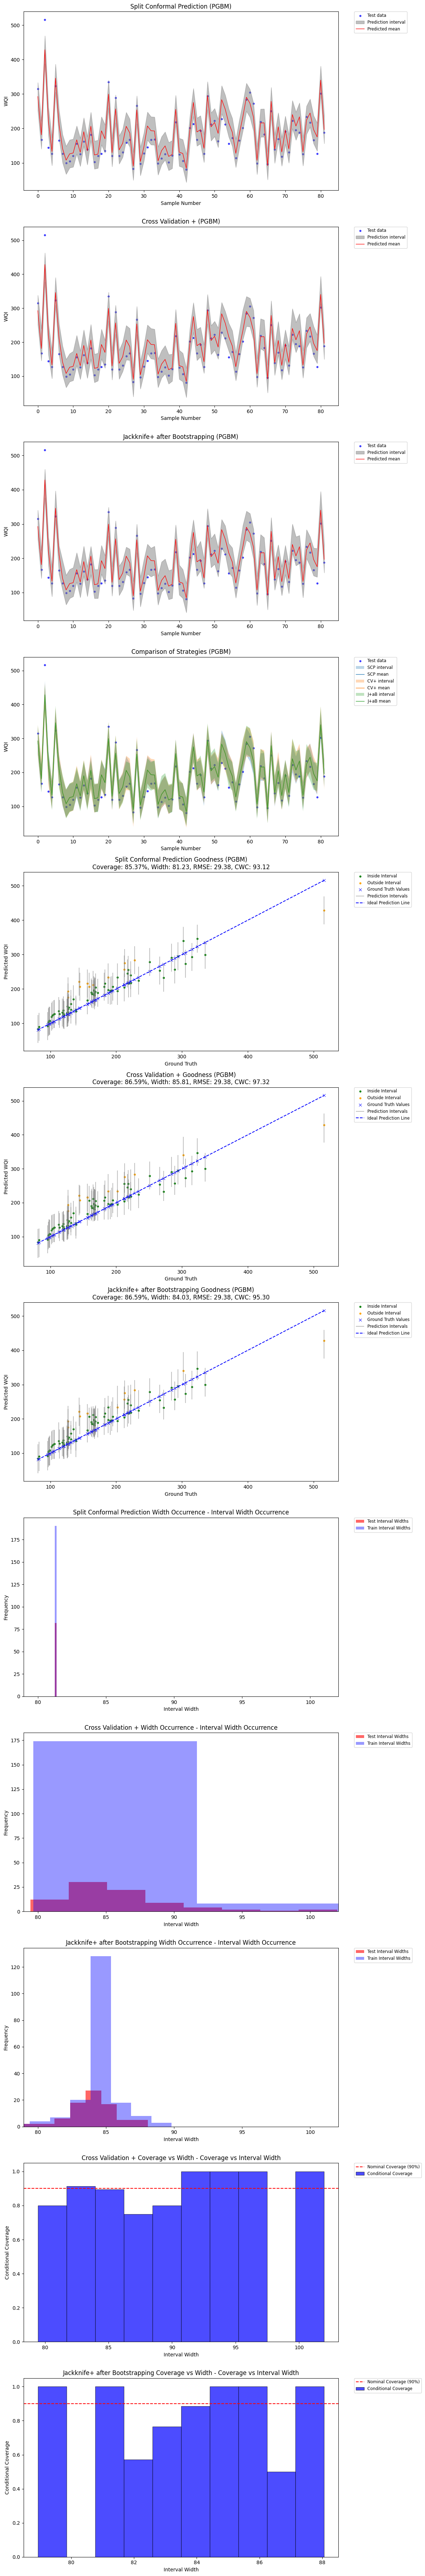

In [48]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax



def conformal_predictions_MAPIE_PGBM(
    model_class,
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name,
    excel_file_path
):
    SEED = 123
    np.random.seed(SEED)
    MISCOVERAGE = ALPHA  # FIX M4: was 0.05
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)

    # Convert y_test to a NumPy array if it has to_numpy
    y_test_np = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test

    # Map method names to descriptive labels
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }

    # Corresponding parameters for each strategy
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Create a base estimator object for each strategy
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    # Fit & predict using MapieRegressor for each strategy
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)


    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred)
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the intervals and predictions for each strategy
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names)*3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(12, 6 * n_figs))
    plot_index = 0

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                            color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red',
                                    label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Comparison subplot (moved after individual strategy plots)
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                        alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name],
                                label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1


    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1


    fig.tight_layout()

    # Save plots to Excel
    # Save plots to Excel
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        sheet_name = 'conformal_predictions_MAPIE'
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        #NEW: Save all predictions/intervals to one worksheet
        all_rows = []
        # Always use y_test_np for consistent array-ness
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = ((y_test_np >= ymin_np) & (y_test_np <= ymax_np)).astype(int)
            residual_np = y_test_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_test_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np,
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet2 = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet2.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet2.cell(row=i+2, column=j, value=float(value) if isinstance(value, np.generic) else value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))



# Example call (assuming best_params, X_train, y_train, X_test, y_test are defined elsewhere)
conformal_predictions_MAPIE_PGBM(
    model_class=PGBMWrapper,
    best_params=best_params,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="PGBM",
    excel_file_path="./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx"
)

In [49]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC_PGBM(
    X_train,
    y_train,
    X_test,
    y_test,
    best_scores_autosampler,
    model_class,
    excel_file_path=None,
    model_params=None,
    alpha=ALPHA  # FIX M4: was 0.1
):
    if model_params is None:
        if model_class.__name__ == 'PGBMWrapper':
            model_params = get_best_model_params(best_scores_autosampler, 'PGBM')
        else:
            model_params = {}

    # Initialize model
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    # Convert to NumPy arrays if needed
    y_train_np = y_train.to_numpy() if isinstance(y_train, pd.Series) else y_train
    model.fit(X_train, y_train_np)

    y_test_np = y_test.to_numpy() if isinstance(y_test, pd.Series) else y_test

    def evaluate_cp(X_test_eval, y_test_eval, model_cp, alpha_val):
        X_test_np = X_test_eval.to_numpy() if isinstance(X_test_eval, pd.DataFrame) else np.array(X_test_eval)
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test_np, alpha=alpha_val)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test_eval, y_pred_lower, y_pred_upper)
        return y_pred, y_pred_lower, y_pred_upper, sharpness, coverage

    # Base predictor setup
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train_np, fit_ratio=0.5)

    y_pred_sc, y_lower_sc, y_upper_sc, sharpness_sc, coverage_sc = evaluate_cp(X_test, y_test_np, splitcp, alpha)

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train_np)
    y_pred, y_lower_cv, y_upper_cv, sharpness_cv, coverage_cv = evaluate_cp(X_test, y_test_np, cvplus, alpha)

    # CQR
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train_np, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_lower_cqr, y_upper_cqr, sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test_np, cqr, alpha)
    y_pred_cqr = 0.5 * (y_lower_cqr + y_upper_cqr)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness_sc:.3f}")
    print(f"SplitCP - Average coverage: {coverage_sc*100:.3f}%")
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cv:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cv*100:.3f}%")
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")


    # Plotting
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    sample_indices = np.arange(len(y_test_np))

    # Plot results for each method
    for idx, (y_pred, y_lower, y_upper, title) in enumerate([
        (y_pred_sc, y_lower_sc, y_upper_sc, 'SplitCP'),
        (y_pred_sc, y_lower_cv, y_upper_cv, 'CVPlus'),
        (y_pred_cqr, y_lower_cqr, y_upper_cqr, 'CQR')
    ]):
        axs[idx].scatter(sample_indices, y_test_np, label='True', color='blue', s=10, alpha=0.7)
        axs[idx].fill_between(sample_indices, y_lower, y_upper, color='gray', alpha=0.5, label='Prediction interval')
        axs[idx].plot(sample_indices, y_pred, color='red', label='Predicted mean', linewidth=1)
        axs[idx].set_title(f'{title}: Prediction Intervals with Conformal Prediction')
        axs[idx].set_xlabel('Sample Number')
        axs[idx].set_ylabel(f'{TARGET_LABEL}')
        axs[idx].legend(fontsize='small')

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_sc).reshape(-1),
        'SplitCP_lower': np.asarray(y_lower_sc).reshape(-1),
        'SplitCP_upper': np.asarray(y_upper_sc).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_sc).reshape(-1),
        'CVPlus_lower': np.asarray(y_lower_cv).reshape(-1),
        'CVPlus_upper': np.asarray(y_upper_cv).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

# Example usage (assuming X_train, y_train, X_test, y_test, best_scores_autosampler exist):
conformal_predictions_PUNCC_PGBM(
    X_train, y_train,
    X_test, y_test,
    best_scores_autosampler=best_scores_autosampler,
    model_class=PGBMWrapper,
    excel_file_path="./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx",
    alpha=0.1
)


Training on CPU
Estimator 0/300, Train metric: 78.9001
Estimator 1/300, Train metric: 76.0510
Estimator 2/300, Train metric: 73.3512
Estimator 3/300, Train metric: 70.6507
Estimator 4/300, Train metric: 68.2775


Estimator 5/300, Train metric: 65.8602
Estimator 6/300, Train metric: 63.4633
Estimator 7/300, Train metric: 61.1513
Estimator 8/300, Train metric: 59.1168
Estimator 9/300, Train metric: 57.0578
Estimator 10/300, Train metric: 55.1212
Estimator 11/300, Train metric: 53.2731


Estimator 12/300, Train metric: 51.4449
Estimator 13/300, Train metric: 49.6976
Estimator 14/300, Train metric: 48.0189
Estimator 15/300, Train metric: 46.4079
Estimator 16/300, Train metric: 44.8642
Estimator 17/300, Train metric: 43.4459
Estimator 18/300, Train metric: 42.0784


Estimator 19/300, Train metric: 40.7679
Estimator 20/300, Train metric: 39.4945
Estimator 21/300, Train metric: 38.2714
Estimator 22/300, Train metric: 37.0826
Estimator 23/300, Train metric: 35.9078
Estimator 24/300, Train metric: 34.7604


Estimator 25/300, Train metric: 33.7132
Estimator 26/300, Train metric: 32.6903
Estimator 27/300, Train metric: 31.6972
Estimator 28/300, Train metric: 30.7656
Estimator 29/300, Train metric: 29.8942
Estimator 30/300, Train metric: 29.0440
Estimator 31/300, Train metric: 28.2583


Estimator 32/300, Train metric: 27.4161
Estimator 33/300, Train metric: 26.6307
Estimator 34/300, Train metric: 25.8644
Estimator 35/300, Train metric: 25.1647
Estimator 36/300, Train metric: 24.4691
Estimator 37/300, Train metric: 23.8297


... (429 outputs left out)

Estimator 264/300, Train metric: 1.2754
Estimator 265/300, Train metric: 1.2655
Estimator 266/300, Train metric: 1.2567
Estimator 267/300, Train metric: 1.2476
Estimator 268/300, Train metric: 1.2388
Estimator 269/300, Train metric: 1.2292
Estimator 270/300, Train metric: 1.2201
Estimator 271/300, Train metric: 1.2113
Estimator 272/300, Train metric: 1.2031
Estimator 273/300, Train metric: 1.1930
Estimator 274/300, Train metric: 1.1882
Estimator 275/300, Train metric: 1.1794


Estimator 276/300, Train metric: 1.1713
Estimator 277/300, Train metric: 1.1629
Estimator 278/300, Train metric: 1.1601
Estimator 279/300, Train metric: 1.1518
Estimator 280/300, Train metric: 1.1450
Estimator 281/300, Train metric: 1.1369
Estimator 282/300, Train metric: 1.1286
Estimator 283/300, Train metric: 1.1206
Estimator 284/300, Train metric: 1.1131
Estimator 285/300, Train metric: 1.1049
Estimator 286/300, Train metric: 1.0985
Estimator 287/300, Train metric: 1.0912


Estimator 288/300, Train metric: 1.0837
Estimator 289/300, Train metric: 1.0794
Estimator 290/300, Train metric: 1.0719
Estimator 291/300, Train metric: 1.0642
Estimator 292/300, Train metric: 1.0567
Estimator 293/300, Train metric: 1.0495
Estimator 294/300, Train metric: 1.0445
Estimator 295/300, Train metric: 1.0403
Estimator 296/300, Train metric: 1.0335
Estimator 297/300, Train metric: 1.0265
Estimator 298/300, Train metric: 1.0197
Estimator 299/300, Train metric: 1.0128


SplitCP - Average prediction intervals width (sharpness): 120.536
SplitCP - Average coverage: 93.902%
CVPlus - Average prediction intervals width (sharpness): 77.798
CVPlus - Average coverage: 84.146%
CQR - Average prediction intervals width (sharpness): 118.208
CQR - Average coverage: 86.585%


In [50]:
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, PGBMWrapper, best_params,"./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx", "PGBM Prediction Intervals")

Training on CPU
Estimator 0/300, Train metric: 78.9001
Estimator 1/300, Train metric: 76.0510
Estimator 2/300, Train metric: 73.3512
Estimator 3/300, Train metric: 70.6507
Estimator 4/300, Train metric: 68.2775
Estimator 5/300, Train metric: 65.8602


Estimator 6/300, Train metric: 63.4633
Estimator 7/300, Train metric: 61.1513
Estimator 8/300, Train metric: 59.1168
Estimator 9/300, Train metric: 57.0578
Estimator 10/300, Train metric: 55.1212
Estimator 11/300, Train metric: 53.2731
Estimator 12/300, Train metric: 51.4449


Estimator 13/300, Train metric: 49.6976
Estimator 14/300, Train metric: 48.0189
Estimator 15/300, Train metric: 46.4079
Estimator 16/300, Train metric: 44.8642
Estimator 17/300, Train metric: 43.4459
Estimator 18/300, Train metric: 42.0784
Estimator 19/300, Train metric: 40.7679


Estimator 20/300, Train metric: 39.4945
Estimator 21/300, Train metric: 38.2714
Estimator 22/300, Train metric: 37.0826
Estimator 23/300, Train metric: 35.9078
Estimator 24/300, Train metric: 34.7604
Estimator 25/300, Train metric: 33.7132
Estimator 26/300, Train metric: 32.6903


Estimator 27/300, Train metric: 31.6972
Estimator 28/300, Train metric: 30.7656
Estimator 29/300, Train metric: 29.8942
Estimator 30/300, Train metric: 29.0440
Estimator 31/300, Train metric: 28.2583
Estimator 32/300, Train metric: 27.4161


Estimator 33/300, Train metric: 26.6307
Estimator 34/300, Train metric: 25.8644
Estimator 35/300, Train metric: 25.1647
Estimator 36/300, Train metric: 24.4691
Estimator 37/300, Train metric: 23.8297
Estimator 38/300, Train metric: 23.2033


... (2,555 outputs left out)

Estimator 275/300, Train metric: 1.0829
Estimator 276/300, Train metric: 1.0786
Estimator 277/300, Train metric: 1.0793
Estimator 278/300, Train metric: 1.0748
Estimator 279/300, Train metric: 1.0707
Estimator 280/300, Train metric: 1.0663
Estimator 281/300, Train metric: 1.0622


Estimator 282/300, Train metric: 1.0579
Estimator 283/300, Train metric: 1.0540
Estimator 284/300, Train metric: 1.0500
Estimator 285/300, Train metric: 1.0461
Estimator 286/300, Train metric: 1.0426
Estimator 287/300, Train metric: 1.0382
Estimator 288/300, Train metric: 1.0330
Estimator 289/300, Train metric: 1.0290


Estimator 290/300, Train metric: 1.0252
Estimator 291/300, Train metric: 1.0214
Estimator 292/300, Train metric: 1.0177
Estimator 293/300, Train metric: 1.0140
Estimator 294/300, Train metric: 1.0122
Estimator 295/300, Train metric: 1.0086
Estimator 296/300, Train metric: 1.0045
Estimator 297/300, Train metric: 1.0008


Estimator 298/300, Train metric: 0.9971
Estimator 299/300, Train metric: 0.9935


# **Conformal Predictions with TabNet**

In [51]:
best_params = get_best_model_params(best_scores_autosampler, 'TabNet')
print(best_params)

{'n_d': 64, 'n_a': 32, 'n_steps': 3, 'gamma': 1.0, 'lambda_sparse': 0.01, 'optimizer_params': {'lr': 0.02}, 'mask_type': 'entmax', 'n_shared': 1, 'n_independent': 2, 'scheduler_params': {'step_size': 10, 'gamma': 0.9}, 'scheduler_fn': <class 'torch.optim.lr_scheduler.StepLR'>, 'seed': 42, 'verbose': 0}


In [52]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class TabNetRegressorCP(TabNetRegressor):
    def fit(self, X, y, *args, **kwargs):
        y_ = np.array(y)
        if y_.ndim == 1:
            y_ = y_.reshape(-1, 1)
        return super().fit(X, y_, *args, **kwargs)
    def predict(self, X, *args, **kwargs):
        preds = super().predict(X, *args, **kwargs)
        return preds.flatten()
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.mean((y_arr >= int_pred[strat_name][:, 0]) & (y_arr <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.sqrt(mean_squared_error(y_arr, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        y_arr = np.array(y_test)
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_arr[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) &
                                           (y_arr[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan)
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages
class visualize:
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        y_true_np = np.array(y_true).ravel()
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')
        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)],
                 linestyle='--', color='blue', label='Ideal Prediction Line')
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')
        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()
        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]
        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE_tabnet(
    model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path
):
    is_tabnet = ("TabNet" in model_name or "TabNet" in model_class.__name__)

    # Remove 'verbose' if present to avoid TypeError in TabNet
    if isinstance(best_params, dict) and "verbose" in best_params:
        best_params = dict(best_params) # make a copy!
        best_params.pop("verbose", None)

    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    MISCOVERAGE = ALPHA  # FIX M4
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 5},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {}

    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(np.array(X_train), np.array(y_train))
        y_pred_raw, int_pred_raw = mapie.predict(np.array(X_test), alpha=MISCOVERAGE)
        y_pred[strat_name] = y_pred_raw.flatten()
        int_pred[strat_name] = np.array(int_pred_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train_raw, int_pred_train_raw = mapie.predict(np.array(X_train), alpha=MISCOVERAGE)
        y_pred_train[strat_name] = y_pred_train_raw.flatten()
        int_pred_train[strat_name] = np.array(int_pred_train_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # All metric calls now use np.array(y_test)
    coverages = validate.coverage(int_pred, np.array(y_test))
    widths = validate.width(int_pred)
    rmse_vals = validate.rmse(y_pred, np.array(y_test))
    cwc_vals = validate.cwc(int_pred, np.array(y_test), MISCOVERAGE)

    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            rmse = rmse_vals[strat_name]
            interval_width = widths[strat_name]
            coverage = coverages[strat_name]
            cwc = cwc_vals[strat_name]
            ssc = np.mean((np.array(y_test) - y_pred[strat_name])**2 +
                          (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)
            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}\n")

    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS = N_BINS  # FIX D4
    n_figs = len(strategies_names) * 3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))
    plot_index = 0

    # Individual strategy plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)
    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()
            axs[plot_index] = visualize.goodness(
                np.array(y_test), y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})',
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages = validate.cond_coverage(int_pred, np.array(y_test), num_bins=NUM_BINS)
    for _strat in _strategies:
        axs[plot_index] = visualize.coverage_by_width(
            np.array(y_test), int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = f'conformal_predictions_MAPIE_{model_name}'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        # Tabular export
        all_rows = []
        y_true_np = np.array(y_test).ravel()
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np
            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)
        all_pred_sheet_name = 'all_pred_values_' + model_name
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1
        worksheet = workbook.create_sheet(title=all_pred_sheet_name)
        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()


conformal_predictions_MAPIE_tabnet(
    TabNetRegressorCP,        # <------ use the wrapper here!
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    "TabNet",
    "./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx"
)

epoch 0  | loss: 36640.99219|  0:00:00s
epoch 1  | loss: 35910.56641|  0:00:00s
epoch 2  | loss: 35213.46875|  0:00:00s
epoch 3  | loss: 34383.80078|  0:00:00s
epoch 4  | loss: 33322.13672|  0:00:00s


epoch 5  | loss: 32416.22461|  0:00:00s
epoch 6  | loss: 31537.16797|  0:00:00s
epoch 7  | loss: 30494.89258|  0:00:00s
epoch 8  | loss: 29223.20703|  0:00:00s
epoch 9  | loss: 28033.83789|  0:00:00s


epoch 10 | loss: 26922.03906|  0:00:00s
epoch 11 | loss: 25540.20898|  0:00:00s
epoch 12 | loss: 24078.70508|  0:00:00s
epoch 13 | loss: 22806.91211|  0:00:00s
epoch 14 | loss: 21269.71094|  0:00:00s


epoch 15 | loss: 19717.92383|  0:00:00s
epoch 16 | loss: 18163.32227|  0:00:00s
epoch 17 | loss: 16595.51172|  0:00:00s
epoch 18 | loss: 15046.75684|  0:00:00s
epoch 19 | loss: 13552.44922|  0:00:00s


epoch 20 | loss: 12121.57324|  0:00:01s
epoch 21 | loss: 10682.2373|  0:00:01s
epoch 22 | loss: 9308.67676|  0:00:01s
epoch 23 | loss: 8115.43555|  0:00:01s
epoch 24 | loss: 6945.02197|  0:00:01s


epoch 25 | loss: 5841.77051|  0:00:01s
epoch 26 | loss: 4816.6123|  0:00:01s
epoch 27 | loss: 3836.40698|  0:00:01s
epoch 28 | loss: 2950.11987|  0:00:01s
epoch 29 | loss: 2183.98169|  0:00:01s


... (1,288 outputs left out)

epoch 87 | loss: 7.35667 |  0:00:03s
epoch 88 | loss: 5.33733 |  0:00:03s
epoch 89 | loss: 5.04255 |  0:00:03s
epoch 90 | loss: 4.15294 |  0:00:03s
epoch 91 | loss: 4.30735 |  0:00:04s


epoch 92 | loss: 4.43208 |  0:00:04s
epoch 93 | loss: 2.50648 |  0:00:04s
epoch 94 | loss: 6.54346 |  0:00:04s
epoch 95 | loss: 5.97395 |  0:00:04s
epoch 96 | loss: 4.01104 |  0:00:04s


epoch 97 | loss: 3.48456 |  0:00:04s
epoch 98 | loss: 3.79692 |  0:00:04s
epoch 99 | loss: 2.90902 |  0:00:04s


Strategy: Split Conformal Prediction
  RMSE: 30.8689
  Interval Width: 93.2715
  Coverage: 92.68%
  CWC: 93.2715
  SSC: 9652.4695

Strategy: Cross Validation +
  RMSE: 30.8689
  Interval Width: 148.8051
  Coverage: 100.00%
  CWC: 148.8051
  SSC: 24645.0543

Strategy: Jackknife+ after Bootstrapping
  RMSE: 30.8689
  Interval Width: 106.7983
  Coverage: 97.56%
  CWC: 106.7983
  SSC: 12371.0842



In [53]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

def conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Get best parameters if not supplied
    if model_params is None:
        model_params = get_best_model_params(best_scores_autosampler, 'TabNet')
        if "verbose" in model_params:
            model_params = dict(model_params)
            model_params.pop("verbose", None)

    model_class = TabNetRegressorCP

    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing TabNet: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_te, y_te, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_te, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(np.array(y_te), y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Base predictor
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    picp_splitcp = np.mean((np.array(y_test).ravel() >= y_pred_lower_splitcp) &
                           (np.array(y_test).ravel() <= y_pred_upper_splitcp))
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")
    print(f"SplitCP - PICP: {picp_splitcp*100:.3f}%")

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness_cvplus, coverage_cvplus = evaluate_cp(X_test, y_test, cvplus, alpha)
    picp_cvplus = np.mean((np.array(y_test).ravel() >= y_pred_lower_cvplus) &
                          (np.array(y_test).ravel() <= y_pred_upper_cvplus))
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cvplus:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cvplus*100:.3f}%")
    print(f"CVPlus - PICP: {picp_cvplus*100:.3f}%\n")

    # CQR
    from sklearn.model_selection import train_test_split
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test, cqr, alpha)
    picp_cqr = np.mean((np.array(y_test).ravel() >= y_pred_lower_cqr) &
                       (np.array(y_test).ravel() <= y_pred_upper_cqr))
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")
    print(f"CQR - PICP: {picp_cqr*100:.3f}%\n")

    # Plot
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    arr_y_test = np.array(y_test).ravel()
    axs[0].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(arr_y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[1].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[2].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(arr_y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export ---
    results_dict = {
        'SplitCP_true': arr_y_test.reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': arr_y_test.reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': arr_y_test.reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC_TabNet')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_TabNet_values')

    plt.close(fig)


conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path="./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    model_params=best_params  # your best params for TabNet
)

SplitCP - Average prediction intervals width (sharpness): 111.029
SplitCP - Average coverage: 91.463%
SplitCP - PICP: 91.463%


CVPlus - Average prediction intervals width (sharpness): 130.187
CVPlus - Average coverage: 98.780%
CVPlus - PICP: 98.780%



CQR - Average prediction intervals width (sharpness): 132.834
CQR - Average coverage: 82.927%
CQR - PICP: 82.927%



In [54]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params,
    excel_file_path=None,
    suptitle: str = "TabNet Prediction Intervals"
) -> None:
    # Use wrapper for TabNet
    model_cls = TabNetRegressorCP

    # Train model with MAPIE
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [np.array(y_train).min(), np.array(y_train).max()],
            [np.array(y_train).min(), np.array(y_train).max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        np.array(y_train).ravel(),
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        np.array(y_test).ravel(),
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        # Use a fresh model each time (sklearn style)
        mapie = MapieRegressor(model_cls(**model_params), **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_2')

    plt.close(fig)

# Helper method for Excel plotting export
def save_plot_to_excel(fig, excel_file_path, sheet_name):
    import io
    from openpyxl import load_workbook
    from openpyxl.drawing.image import Image
    from PIL import Image as PILImage
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PILImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)
        worksheet.add_image(img, 'A1')
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))


prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params=best_params,
    excel_file_path="./drive/MyDrive/Regression/water_quality_wqi_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    suptitle="TabNet Prediction Intervals"
)